### **01_Synthetic — PRML Assignment 8**

Comparing GMM, LDA, KNN, and SVM on synthetic data (Original features vs. top-K PCA projections).

### **Imports**

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

from src import GMMClassifier, LDA, KNN, SVM, PCA, StandardScaler, LCG


### **Load and Split Data**

In [2]:
data_path = "../Datasets/SyntheticData/data.pkl"

with open(data_path, "rb") as file:
    data = pickle.load(file)

X = np.asarray(data["x"], dtype=float)
y = np.asarray(data["y"]).ravel()

# Shuffle and split into 60% train, 20% validation, 20% test using LCG
lcg = LCG(seed=42)
indices = lcg.permutation(len(y))
X, y = X[indices], y[indices]

train_end = int(0.6 * len(y))
val_end = int(0.8 * len(y))

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Class counts in train:", np.unique(y_train, return_counts=True))

Train: (12000, 16) Validation: (4000, 16) Test: (4000, 16)
Class counts in train: (array([0, 1]), array([5959, 6041]))


### **Feature Standardization**

In [3]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# Setup classes and results dictionary for evaluation
classes = np.unique(y_train)
label_to_idx = {int(c): i for i, c in enumerate(classes)}
results = {}

### **Classifiers on Original Features**


### **1. Gaussian Mixture Model (GMM)**


In [4]:
# Train and evaluate GMM on original features
gmm = GMMClassifier(K=3, reg=1e-3)
gmm.fit(X_train_s, y_train)

val_pred = gmm.predict(X_val_s)
test_pred = gmm.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

GMM original     | Validation: 0.9688 | Test: 0.9643
Confusion matrix:
 [[1891   85]
 [  58 1966]]


### **2. Linear Discriminant Analysis (LDA)**


In [5]:
# Train and evaluate LDA on original features
lda = LDA()
lda.fit(X_train_s, y_train)

val_pred = lda.predict(X_val_s)
test_pred = lda.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

LDA original     | Validation: 0.9263 | Test: 0.9285
Confusion matrix:
 [[1820  156]
 [ 130 1894]]


### **3. K-Nearest Neighbours (KNN)**


In [6]:
# Train and evaluate KNN on original features
knn = KNN(k=5)
knn.fit(X_train_s, y_train)

val_pred = knn.predict(X_val_s)
test_pred = knn.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

KNN original     | Validation: 0.9940 | Test: 0.9935
Confusion matrix:
 [[1961   15]
 [  11 2013]]


### **4. Support Vector Machine (SVM)**


In [7]:
# Train and evaluate SVM on original features
svm = SVM(kernel="rbf", C=1.0, max_train=1500)
svm.fit(X_train_s, y_train)

val_pred = svm.predict(X_val_s)
test_pred = svm.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

SVM original     | Validation: 0.9902 | Test: 0.9878
Confusion matrix:
 [[1954   22]
 [  27 1997]]


### **Dimensionality Reduction with PCA**

In [8]:
K = 8
pca = PCA(n_components=K).fit(X_train_s)
X_train_p = pca.transform(X_train_s)
X_val_p = pca.transform(X_val_s)
X_test_p = pca.transform(X_test_s)

print(f"Retained variance with K={K}:", round(float(pca.explained_variance_ratio_.sum()), 4))

Retained variance with K=8: 0.7268


### **Classifiers on PCA Features**


### **1. GMM on PCA Features**


In [9]:
# Train and evaluate GMM on PCA features
gmm_p = GMMClassifier(K=3, reg=1e-3)
gmm_p.fit(X_train_p, y_train)

val_pred = gmm_p.predict(X_val_p)
test_pred = gmm_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

GMM PCA          | Validation: 0.9547 | Test: 0.9525
Confusion matrix:
 [[1873  103]
 [  87 1937]]


### **2. LDA on PCA Features**


In [10]:
# Train and evaluate LDA on PCA features
lda_p = LDA()
lda_p.fit(X_train_p, y_train)

val_pred = lda_p.predict(X_val_p)
test_pred = lda_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

LDA PCA          | Validation: 0.8815 | Test: 0.8815
Confusion matrix:
 [[1702  274]
 [ 200 1824]]


### **3. KNN on PCA Features**


In [11]:
# Train and evaluate KNN on PCA features
knn_p = KNN(k=5)
knn_p.fit(X_train_p, y_train)

val_pred = knn_p.predict(X_val_p)
test_pred = knn_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

KNN PCA          | Validation: 0.9690 | Test: 0.9677
Confusion matrix:
 [[1902   74]
 [  55 1969]]


### **4. SVM on PCA Features**


In [12]:
# Train and evaluate SVM on PCA features
svm_p = SVM(kernel="rbf", C=1.0, max_train=1500)
svm_p.fit(X_train_p, y_train)

val_pred = svm_p.predict(X_val_p)
test_pred = svm_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

SVM PCA          | Validation: 0.9667 | Test: 0.9667
Confusion matrix:
 [[1898   78]
 [  55 1969]]


### **Results Comparison**

GMM original     | Validation: 0.9688 | Test: 0.9643
LDA original     | Validation: 0.9263 | Test: 0.9285
KNN original     | Validation: 0.9940 | Test: 0.9935
SVM original     | Validation: 0.9902 | Test: 0.9878
GMM PCA          | Validation: 0.9547 | Test: 0.9525
LDA PCA          | Validation: 0.8815 | Test: 0.8815
KNN PCA          | Validation: 0.9690 | Test: 0.9677
SVM PCA          | Validation: 0.9667 | Test: 0.9667


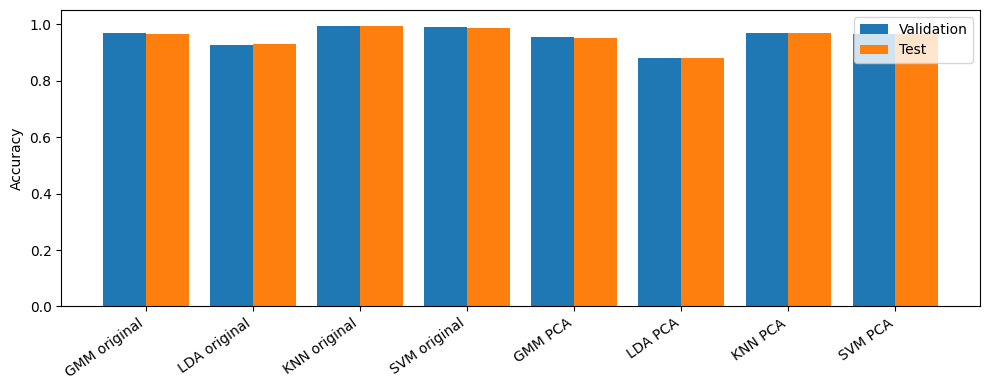

In [13]:
for name, (val_acc, test_acc) in results.items():
    print(f"{name:16s} | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")

names = list(results.keys())
x_pos = np.arange(len(names))

plt.figure(figsize=(10, 4))
plt.bar(x_pos - 0.2, [results[n][0] for n in names], width=0.4, label="Validation")
plt.bar(x_pos + 0.2, [results[n][1] for n in names], width=0.4, label="Test")
plt.xticks(x_pos, names, rotation=35, ha="right")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### **Observations and Inferences**

- Non-linear classifiers (KNN, SVM, GMM) achieve high accuracy on complex cluster boundaries.
- Projecting to K=8 PCA dimensions retains key variation with consistent classification performance.